P(King | Face) card: 0.3333
Die: E[X] = 3.5000, Var(X) = 2.9167 SD = 1.7078
0.420881199680712
0.4208811819553375


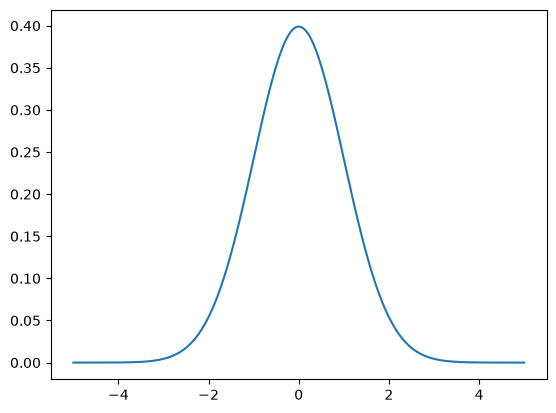

In [ ]:
import math
import random
import torch
import torch.nn as nn

def factorial(n):
    result = 1
    for i in range(2, n+1):
        result *= i
    return result

def combinations(n, k):
    return factorial(n) / factorial(k) * factorial(n-k)

def prob_condicional(p_a_and_b, p_b):
    return p_a_and_b / p_b

p_king_given_face = prob_condicional(4/52, 12/52)
print(f'P(King | Face) card: {p_king_given_face:.4f}')

#PMF AND PDF
def bernoulli_pm(k, p):
    return p if k == 1 else (1 - p)

def categorical_pmf(k, probs):
    return probs[k]

def poisson_pmf(k, lam):
    return (lam ** k) * math.exp(-lam) / factorial(k)

def uniform_pdf(x, a, b):
    if a <= x <= b:
        return 1.0 / (b-a)
    return 0.0

def normal_pdf(x, mu, sigma):
    coeff = 1.0 / (sigma * math.sqrt(2 * math.pi))
    exponent = -0.5 * ((x - mu) / sigma) ** 2
    return coeff * math.exp(exponent)

def expected_value(values, probs):
    return sum(v * p for v, p in zip(values, probs))

def variance(values, probs):
    mu = expected_value(values, probs)
    return sum(p * (v - mu) ** 2 for v, p in zip(values, probs))

die_values = [1,2,3,4,5,6]
die_probs = [1/6] * 6
mu = expected_value(die_values, die_probs)
var = variance(die_values, die_probs)

print(f'Die: E[X] = {mu:.4f}, Var(X) = {var:.4f} SD = {var**0.5:.4f}')

def sample_bernoulli(p, n=1):
    return [1 if random.random() < p else 0 for _ in range(n)]

def sample_categorical(probs, n=1):
    cumulative = []
    total = 0
    for p in probs:
        total += p
        cumulative.append(total)
    samples = []
    for _ in range(n):
        r = random.random()
        for i, c in enumerate(cumulative):
            if r <= c:
                samples.append(i)
                break
    return samples

def sample_normal_box_muller(mu, sigma, n=1):
    samples = []
    for _ in range(n):
        u1 = random.random()
        u2 = random.random()
        z = math.sqrt(-2 * math.log(u1)) * math.cos(2*math.pi*u2)
        samples.append(mu + sigma * z)
    return samples

def softmax(logits):
    max_logit = max(logits)
    shifted = [z - max_logit for z in logits]
    exps = [math.exp(z) for z in shifted]
    total = sum(exps)
    return [e / total for e in exps]

def log_softmax(logits):
    max_logit = max(logits)
    shifted = [z - max_logit for z in logits]
    log_sum_exp = max_logit + math.log(sum(math.exp(z) for z in shifted))
    return [z - log_sum_exp for z in logits]

def cross_entropy_loss(logits, target_index):
    log_probs = log_softmax(logits)
    return -log_probs[target_index]

#EXERCICIO 3 - PROBABILITY AND DISTRIBUTION
logits = [2.0, 0.5, -1, 3.0, 0.1]
target_index = 3

entropia = cross_entropy_loss(logits, 3)

print(entropia)
criterion = nn.CrossEntropyLoss()
logits_tensor = torch.tensor([logits], dtype=torch.float32)  # shape: (1, 5)
target_tensor = torch.tensor([target_index], dtype=torch.long)  # shape: (1,)

loss_pytorch = criterion(logits_tensor, target_tensor).item()
print(loss_pytorch)

def demonstrate_tcl(dist_fn, n_samples, n_averages):
    averages = []
    for _ in range(n_averages):
        samples = [dist_fn() for _ in range(n_samples)]
        averages.append(sum(samples) / len(samples))
    return averages

import matplotlib.pyplot as plt

mu = 0.0
sigma = 1.0

xs = [mu + 1.0 * (i-500) / 100 for i in range(1001)]
ys = [normal_pdf(x, mu, sigma) for x in xs]
plt.plot(xs, ys)
plt.show()